In [2]:
import pandas as pd

df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)

print(df.shape)
print(df["TotalCharges"].dtype)
print(df["Churn_flag"].mean().round(4))

(7043, 22)
float64
0.2654


In [3]:
print(df.groupby("Contract")["Churn_flag"].agg(["count", "mean"]).round(3))
print()

df["tenure_group"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72],
                            labels=["0-12", "13-24", "25-48", "49-72"])
print(df.groupby("tenure_group", observed=True)["Churn_flag"].agg(["count", "mean"]).round(3))
print()

print(df.groupby("InternetService")["Churn_flag"].agg(["count", "mean"]).round(3))
print()

print(df.groupby("PaymentMethod")["Churn_flag"].agg(["count", "mean"]).round(3))


                count   mean
Contract                    
Month-to-month   3875  0.427
One year         1473  0.113
Two year         1695  0.028

              count   mean
tenure_group              
0-12           2186  0.474
13-24          1024  0.287
25-48          1594  0.204
49-72          2239  0.095

                 count   mean
InternetService              
DSL               2421  0.190
Fiber optic       3096  0.419
No                1526  0.074

                           count   mean
PaymentMethod                          
Bank transfer (automatic)   1544  0.167
Credit card (automatic)     1522  0.152
Electronic check            2365  0.453
Mailed check                1612  0.191


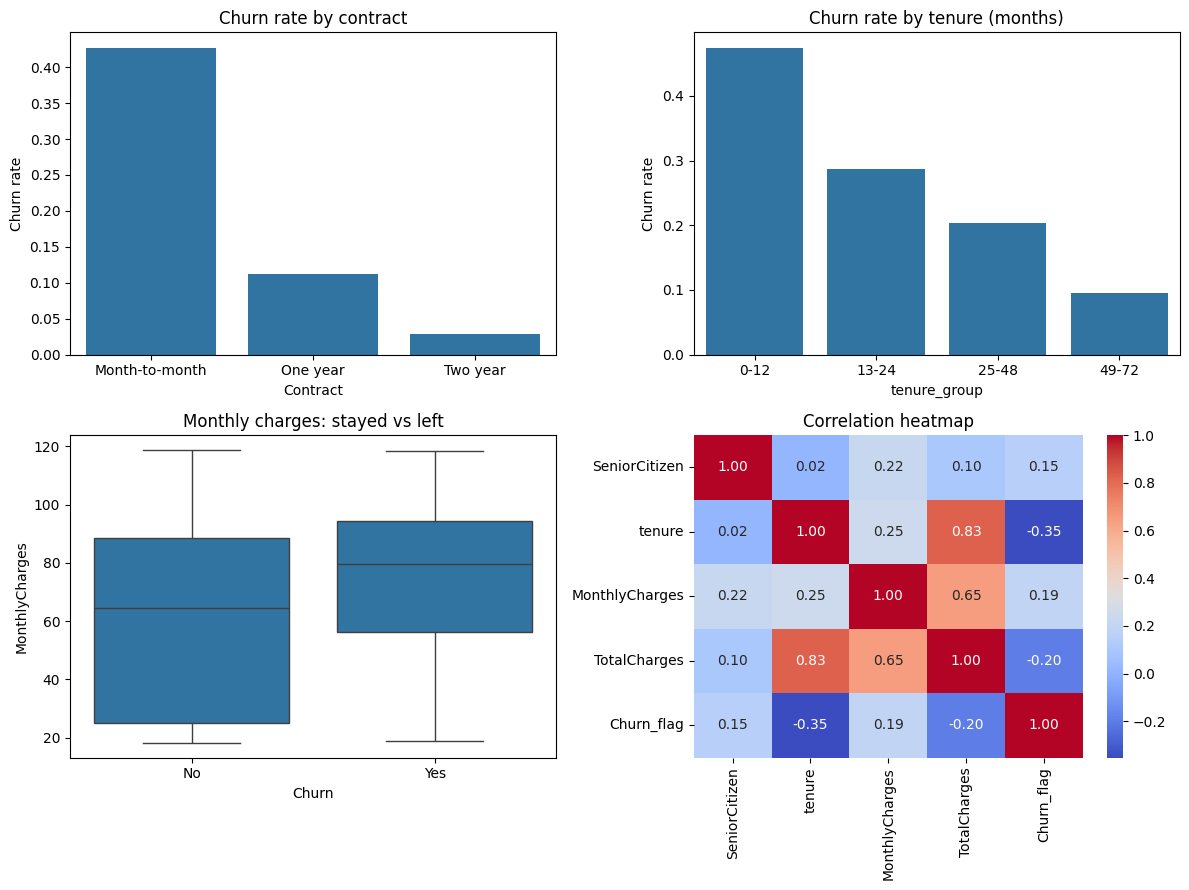

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.barplot(data=df, x="Contract", y="Churn_flag", errorbar=None, ax=axes[0, 0])
axes[0, 0].set_title("Churn rate by contract")
axes[0, 0].set_ylabel("Churn rate")

sns.barplot(data=df, x="tenure_group", y="Churn_flag", errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title("Churn rate by tenure (months)")
axes[0, 1].set_ylabel("Churn rate")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1, 0])
axes[1, 0].set_title("Monthly charges: stayed vs left")

corr = df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "Churn_flag"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Correlation heatmap")

plt.tight_layout()
plt.savefig("churn_eda.png", dpi=150)
plt.show()

df.to_csv("telco_cleaned.csv", index=False)


In [5]:
import sqlite3

conn = sqlite3.connect("telco.db")
df.assign(tenure_group=df["tenure_group"].astype(str)).to_sql("customers", conn, if_exists="replace", index=False)

print(pd.read_sql("SELECT COUNT(*) AS customers, SUM(Churn_flag) AS churned FROM customers", conn))


   customers  churned
0       7043     1869


In [7]:
q1 = """
SELECT Contract,
       COUNT(*) AS customers,
       SUM(Churn_flag) AS churned,
       ROUND(100.0 * SUM(Churn_flag) / COUNT(*), 1) AS churn_pct
FROM customers
GROUP BY Contract
ORDER BY churn_pct DESC
"""
print(pd.read_sql(q1, conn))

q2 = """
WITH overall AS (
    SELECT 1.0 * SUM(Churn_flag) / COUNT(*) AS overall_rate
    FROM customers
),
by_contract AS (
    SELECT Contract,
           COUNT(*) AS customers,
           1.0 * SUM(Churn_flag) / COUNT(*) AS rate
    FROM customers
    GROUP BY Contract
)
SELECT b.Contract,
       b.customers,
       ROUND(100 * b.rate, 1) AS churn_pct,
       ROUND(100 * o.overall_rate, 1) AS overall_pct,
       ROUND(b.rate / o.overall_rate, 2) AS times_overall
FROM by_contract b
CROSS JOIN overall o
ORDER BY b.rate DESC
"""
print(pd.read_sql(q2, conn))

         Contract  customers  churned  churn_pct
0  Month-to-month       3875     1655       42.7
1        One year       1473      166       11.3
2        Two year       1695       48        2.8
         Contract  customers  churn_pct  overall_pct  times_overall
0  Month-to-month       3875       42.7         26.5           1.61
1        One year       1473       11.3         26.5           0.42
2        Two year       1695        2.8         26.5           0.11


In [8]:
q3 = """
WITH seg AS (
    SELECT Contract, InternetService,
           COUNT(*) AS customers,
           1.0 * SUM(Churn_flag) / COUNT(*) AS rate
    FROM customers
    GROUP BY Contract, InternetService
)
SELECT Contract, InternetService, customers,
       ROUND(100 * rate, 1) AS churn_pct,
       RANK() OVER (ORDER BY rate DESC) AS risk_rank
FROM seg
WHERE customers >= 100
ORDER BY risk_rank
"""
print(pd.read_sql(q3, conn))

q4 = """
WITH m AS (
    SELECT tenure, SUM(Churn_flag) AS churned
    FROM customers
    GROUP BY tenure
)
SELECT tenure, churned,
       SUM(churned) OVER (ORDER BY tenure) AS running_churned,
       ROUND(100.0 * SUM(churned) OVER (ORDER BY tenure)
             / (SELECT SUM(Churn_flag) FROM customers), 1) AS cum_pct
FROM m
WHERE tenure <= 12
ORDER BY tenure
"""
print(pd.read_sql(q4, conn))

         Contract InternetService  customers  churn_pct  risk_rank
0  Month-to-month     Fiber optic       2128       54.6          1
1  Month-to-month             DSL       1223       32.2          2
2        One year     Fiber optic        539       19.3          3
3  Month-to-month              No        524       18.9          4
4        One year             DSL        570        9.3          5
5        Two year     Fiber optic        429        7.2          6
6        One year              No        364        2.5          7
7        Two year             DSL        628        1.9          8
8        Two year              No        638        0.8          9
    tenure  churned  running_churned  cum_pct
0        0        0                0      0.0
1        1      380              380     20.3
2        2      123              503     26.9
3        3       94              597     31.9
4        4       83              680     36.4
5        5       64              744     39.8
6       

In [9]:
q5 = """
SELECT Contract, customerID, MonthlyCharges, tenure, rn
FROM (
    SELECT Contract, customerID, MonthlyCharges, tenure,
           ROW_NUMBER() OVER (PARTITION BY Contract
                              ORDER BY MonthlyCharges DESC) AS rn
    FROM customers
    WHERE Churn_flag = 1
)
WHERE rn <= 3
ORDER BY Contract, rn
"""
print(pd.read_sql(q5, conn))

q6 = """
WITH pm AS (
    SELECT PaymentMethod, Contract,
           COUNT(*) AS customers,
           1.0 * SUM(Churn_flag) / COUNT(*) AS rate
    FROM customers
    GROUP BY PaymentMethod, Contract
)
SELECT PaymentMethod, Contract, customers,
       ROUND(100 * rate, 1) AS churn_pct,
       RANK() OVER (PARTITION BY Contract ORDER BY rate DESC) AS rank_in_contract
FROM pm
ORDER BY Contract, rank_in_contract
"""
print(pd.read_sql(q6, conn))


         Contract  customerID  MonthlyCharges  tenure  rn
0  Month-to-month  2302-ANTDP          117.45      48   1
1  Month-to-month  4361-BKAXE          114.50      41   2
2  Month-to-month  9158-VCTQB          113.60      41   3
3        One year  8199-ZLLSA          118.35      67   1
4        One year  2889-FPWRM          117.80      72   2
5        One year  1444-VVSGW          115.65      70   3
6        Two year  9053-JZFKV          116.20      67   1
7        Two year  1555-DJEQW          114.20      70   2
8        Two year  5271-YNWVR          113.15      68   3
                PaymentMethod        Contract  customers  churn_pct  \
0            Electronic check  Month-to-month       1850       53.7   
1   Bank transfer (automatic)  Month-to-month        589       34.1   
2     Credit card (automatic)  Month-to-month        543       32.8   
3                Mailed check  Month-to-month        893       31.6   
4            Electronic check        One year        347       18